Normalization is a technique often applied as part of data preparation for machine learning. the goal of normalization is to change the values of numeric columns in the dataset to use a common scale ,without distorting differences in the ranges of values or losing information

MinMaxScaling [0,1]

In [1]:
import numpy as np

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv("wine_data.csv",header=None,usecols=[0,1,2])
df.columns=['Class label','Alcohol' ,'Malic Acid']

In [6]:
df

,Class label,Alcohol,Malic Acid
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36
3,1,14.37,1.95
4,1,13.24,2.59
...,...,...,...
173,3,13.71,5.65
174,3,13.40,3.91
175,3,13.27,4.28
176,3,13.17,2.59


<Axes: xlabel='Alcohol', ylabel='Density'>

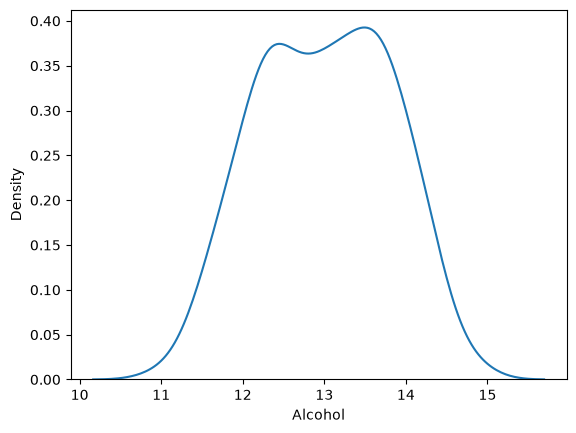

In [7]:
sns.kdeplot(df['Alcohol'])

<Axes: xlabel='Alcohol', ylabel='Malic Acid'>

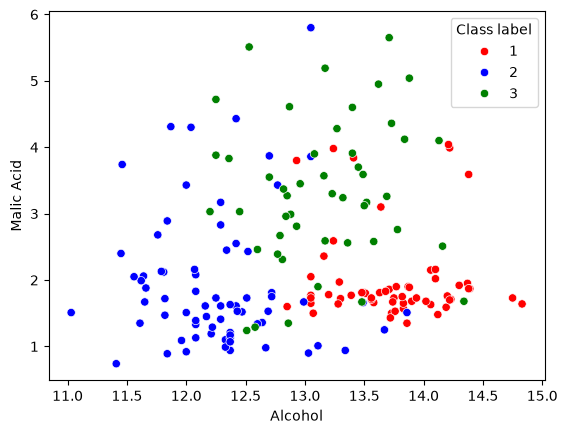

In [9]:
color_dict = {1: 'red', 3: 'green', 2: 'blue'}

sns.scatterplot(
    data=df,
    x='Alcohol',
    y='Malic Acid',
    hue='Class label',
    palette=color_dict
)

In [21]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(df.drop('Class label',axis=1),
                                               df['Class label'],
                                               test_size=0.3,
                                               random_state=42)
X_test.shape,X_train.shape

((54, 2), (124, 2))

In [22]:
from sklearn.preprocessing import MinMaxScaler

scaler= MinMaxScaler()
#fit the scaler to the train set
scaler.fit(X_train)
#transform train and test sets
X_train_scaled=scaler.transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [23]:
X_test_scaled=pd.DataFrame(X_test_scaled,columns=X_train.columns)
X_train_scaled=pd.DataFrame(X_test_scaled,columns=X_test.columns)


In [24]:
np.round(X_train.describe(),1)

,Alcohol,Malic Acid
count,124.0,124.0
mean,13.0,2.4
std,0.8,1.1
min,11.0,0.9
25%,12.3,1.6
50%,12.9,1.9
75%,13.7,3.2
max,14.8,5.8


In [25]:
np.round(X_train_scaled.describe(),1)

,Alcohol,Malic Acid
count,54.0,54.0
mean,0.5,0.3
std,0.2,0.2
min,0.1,-0.0
25%,0.4,0.1
50%,0.6,0.2
75%,0.7,0.4
max,0.9,0.9


In [27]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_train_scaled:", X_train_scaled.shape)

X_train: (124, 2)
y_train: (124,)
X_train_scaled: (54, 2)


In [31]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Class label'])
y = df['Class label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)

In [32]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

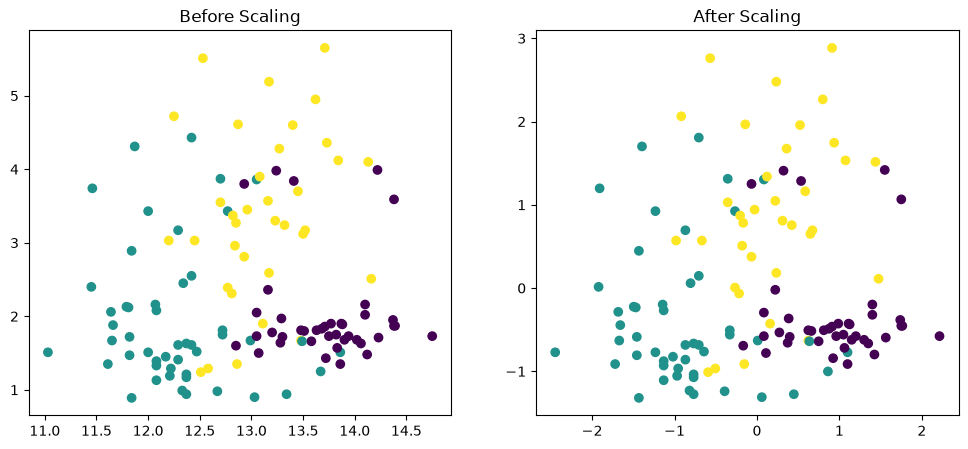

In [34]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

ax1.scatter(
    X_train['Alcohol'],
    X_train['Malic Acid'],
    c=y_train
)
ax1.set_title("Before Scaling")

ax2.scatter(
    X_train_scaled['Alcohol'],
    X_train_scaled['Malic Acid'],
    c=y_train
)
ax2.set_title("After Scaling")

plt.show()

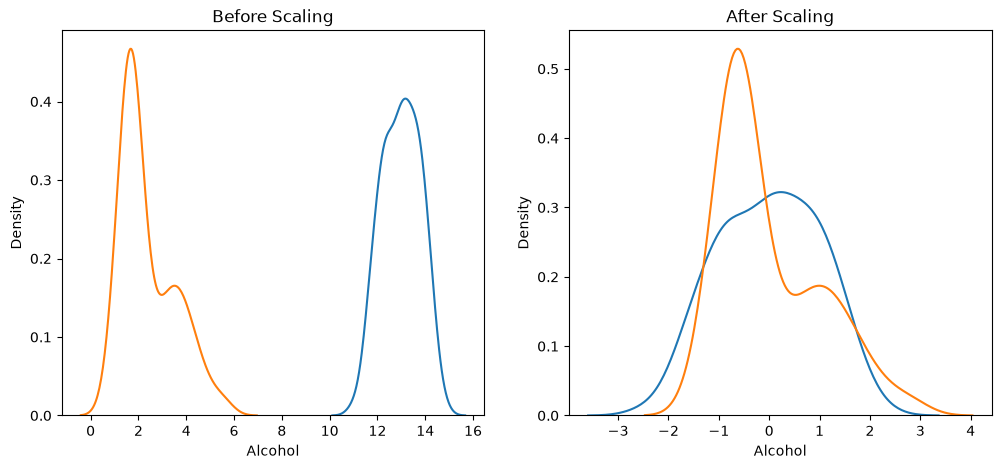

In [35]:
fig, (ax1,ax2)= plt.subplots(ncols=2,figsize=(12,5))

ax1.set_title("Before Scaling")
sns.kdeplot(X_train['Alcohol'],ax=ax1)
sns.kdeplot(X_train['Malic Acid'],ax=ax1)

ax2.set_title("After Scaling")
sns.kdeplot(X_train_scaled['Alcohol'],ax=ax2)
sns.kdeplot(X_train_scaled['Malic Acid'],ax=ax2)
plt.show()



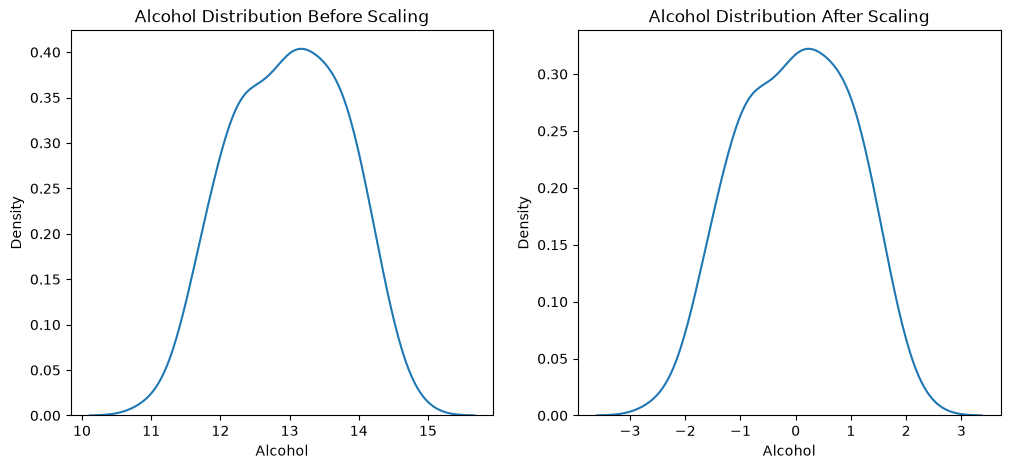

In [36]:
fig, (ax1,ax2) = plt.subplots(ncols=2,figsize=(12,5))
ax1.set_title("Alcohol Distribution Before Scaling")
sns.kdeplot(X_train['Alcohol'],ax=ax1)

ax2.set_title("Alcohol Distribution After Scaling")
sns.kdeplot(X_train_scaled['Alcohol'],ax=ax2)
plt.show()

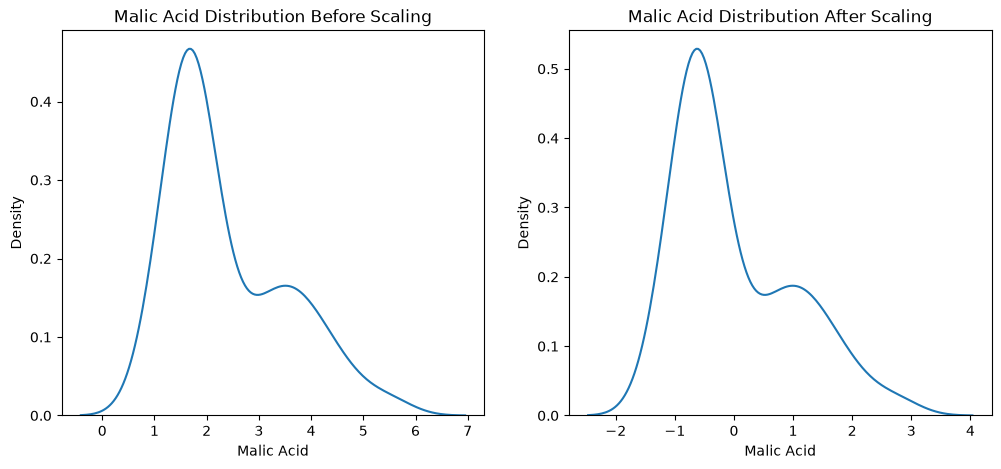

In [37]:
fig, (ax1,ax2) = plt.subplots(ncols=2,figsize=(12,5))
ax1.set_title("Malic Acid Distribution Before Scaling")
sns.kdeplot(X_train['Malic Acid'],ax=ax1)

ax2.set_title("Malic Acid Distribution After Scaling")
sns.kdeplot(X_train_scaled['Malic Acid'],ax=ax2)
plt.show()